In [61]:
%pip install -U langchain-google-genai

  Using cached langchain_google_genai-4.4.2-py3-none-any.whl.metadata (2.7 kB)
Using cached langchain_google_genai-4.4.2-py3-none-any.whl (81 kB)
   ---------------------------------------- 0.0/1.3 MB ? eta -:--:--
   ---------------------------------------- 0.0/1.3 MB ? eta -:--:--
   ---------------------------------------- 0.0/1.3 MB ? eta -:--:--
   -------- ------------------------------- 0.3/1.3 MB ? eta -:--:--
   ---------------- ----------------------- 0.5/1.3 MB 1.4 MB/s eta 0:00:01
   ---------------- ----------------------- 0.5/1.3 MB 1.4 MB/s eta 0:00:01
   ---------------- ----------------------- 0.5/1.3 MB 1.4 MB/s eta 0:00:01
   ---------------- ----------------------- 0.5/1.3 MB 1.4 MB/s eta 0:00:01
   ------------------------- -------------- 0.8/1.3 MB 605.1 kB/s eta 0:00:01
   --------------------------------- ------ 1.0/1.3 MB 619.4 kB/s eta 0:00:01
   --------------------------------- ------ 1.0/1.3 MB 619.4 kB/s eta 0:00:01
   --------------------------------- ---

  You can safely remove it manually.
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
deepagents 0.7.32 requires langchain<2.0.0,>=1.4.7, but you have langchain 1.3.1 which is incompatible.


In [1]:
from langchain_google_genai import ChatGoogleGenerativeAI
from langchain_google_genai import GoogleGenerativeAIEmbeddings
from dotenv import load_dotenv
from langchain_community.document_loaders import PyPDFLoader
from langchain_text_splitters import RecursiveCharacterTextSplitter
from langchain_community.vectorstores import FAISS
from langchain_core.tools import tool
from langgraph.graph import StateGraph, START
from typing import Annotated, TypedDict
from langgraph.graph.message import add_messages
from langchain_core.messages import HumanMessage, BaseMessage
from langgraph.prebuilt import ToolNode, tools_condition

C:\Users\sajal\AppData\Local\Temp\ipykernel_20384\2084080025.py:4: DeprecationWarning: `langchain-community` is being sunset and is no longer actively maintained. See https://github.com/langchain-ai/langchain-community/issues/674 for details and migration guidance toward standalone integration packages.
  from langchain_community.document_loaders import PyPDFLoader


In [2]:
load_dotenv()

True

In [27]:
llm = ChatGoogleGenerativeAI(
    model="gemini-3.6-flash",
    temperature=0
)

In [28]:
response = llm.invoke("Hello! Introduce yourself.")
print(response.content)

c:\Users\sajal\OneDrive\Desktop\agentic-chatbot-series\langgraph\Lib\site-packages\langchain_google_genai\chat_models.py:3919: UserWarning: Model 'gemini-3.6-flash' uses fixed sampling defaults; the sampling parameter(s) temperature will be ignored.
  request = self._build_request_config(


[{'type': 'text', 'text': 'Hello! I am a large language model, trained by Google.\n\nYou can think of me as an AI assistant here to help you with a wide variety of tasks. I can answer questions, help you write or edit text, assist with coding, brainstorm ideas, summarize long articles, and much more. \n\nHow can I help you today?', 'extras': {'signature': 'EsgJCsUJAWkUfRPaK88GlBVgfies5seWkpw8lmmmovoftfP6wfqdVxFKANKo/0j3X19MLCLjiov61RiTfeWSzgAr/hdGVEB5SYJay1FsJNSOaAumrk6VVadkiT8wm3w15gggPORL+eqYwyDDM7WT0uJH5udUJamdrg6AQafW1tUNpsP8TiE9fO2djJgzX5XpMGO60UiyCqXvcv7MguhkLEedFVN7lM/xsyWcwvgwKQzLCgwLucuqOtxKyyPWhJFElGx2k0LoEnUFZ9DoecK0I+qvFsJ0+pVr6OKqB+BtJUNovEp7YGcuPLU5T9S9KJtZO6thfIvY50vWyQR0zztI7LxNDo2SkIpNQXTS3B6RlZ0icJoslH0GNHbMHpV7mjyLE93V/qTn+OY2FhGjPtCuQnRWQ82p2FMQ0/eyO4EU2iOndm2CifWNiAT/gyjZp8IroZXVWD7lL+YSjxaFMSiGC1akn7OZjgeQlWOD0yXvUv51LWu2RUIixmMXf309kiDjaDowZVtauOJMvDiSSltPz+gsguAVxqfYgJkHwYNXU+R12tOErZTbRPhedoNhIbVnz2v9bxVE9EMeYPQsAm/ztq+mGewoJZZUevwVgPrsK20EEE6tS5BNFbGWDp5IrvpkF

In [6]:
loader = PyPDFLoader("Unnati_new_cv (2).pdf")
docs = loader.load()

In [7]:
len(docs)

1

In [8]:
docs

[Document(metadata={'producer': 'pdfTeX-1.40.27', 'creator': 'LaTeX with hyperref', 'creationdate': '2026-10-14T19:04:47+00:00', 'author': '', 'keywords': '', 'moddate': '2026-10-14T19:04:47+00:00', 'ptex.fullbanner': 'This is pdfTeX, Version 3.141592653-2.6-1.40.27 (TeX Live 2025) kpathsea version 6.4.1', 'subject': '', 'title': '', 'trapped': '/False', 'source': 'Unnati_new_cv (2).pdf', 'total_pages': 1, 'page': 0, 'page_label': '1'}, page_content='UNNATI YOGI\nFULL STACK & AI/ML DEVELOPER\n✉unnatiyogi170@gmail.com |♂phone+91 7999641357 |/codeLeetCode |/linkedinLinkedIn |/githubGitHub\nProfile Summary\nDriven Computer Science student and Full Stack & AI/ML Developer with a strong foundation in DSA and software\nengineering. Proficient in React.js, Node.js, Python, MongoDB, Machine Learning, Generative AI, LLMs, and RAG.\nSolved 400+ LeetCode problems, demonstrating strong analytical and problem-solving abilities. Passionate about\nengineering scalable, intelligent, and impactful solu

In [9]:
splitter = RecursiveCharacterTextSplitter(chunk_size=1000, chunk_overlap=200)
chunks = splitter.split_documents(docs)

In [10]:
len(chunks)

4

In [11]:
import sys
print(sys.executable)

c:\Users\sajal\OneDrive\Desktop\agentic-chatbot-series\langgraph\Scripts\python.exe


In [29]:
embeddings = GoogleGenerativeAIEmbeddings(
    model="gemini-embedding-001"
)
vector_store = FAISS.from_documents(chunks, embeddings)
vector_store.save_local("faiss_index")

In [30]:
vector_store

In [31]:
retriever = vector_store.as_retriever(search_type='similarity', search_kwargs={'k':4})

In [15]:
retriever.invoke("What are the different technical skills mentioned in the document")

[Document(id='6eafd0cc-cdea-49ab-8f55-ef0f2e30b460', metadata={'producer': 'pdfTeX-1.40.27', 'creator': 'LaTeX with hyperref', 'creationdate': '2026-10-14T19:04:47+00:00', 'author': '', 'keywords': '', 'moddate': '2026-10-14T19:04:47+00:00', 'ptex.fullbanner': 'This is pdfTeX, Version 3.141592653-2.6-1.40.27 (TeX Live 2025) kpathsea version 6.4.1', 'subject': '', 'title': '', 'trapped': '/False', 'source': 'Unnati_new_cv (2).pdf', 'total_pages': 1, 'page': 0, 'page_label': '1'}, page_content='•Evaluated model performance with classification metrics and refined the model through tuning.\nAchievements\n• Google Developer Groups (GDG) | Co-Lead:Co-led the GDG team, coordinating events, managing team\nactivities, and supporting community engagement.\n•LeetCode:Solved 400+ DSA problems, strengthening problem-solving and algorithmic skills.\nLeadership\n• Club Leader – GeeksforGeeks Coding Club:Led coding activities, encouraged peer participation, and\nsupported students in problem-solving a

In [32]:
@tool
def rag_tool(query: str) -> str:
    """
    Retrieve relevant information from the PDF document.

    Use this tool when the user asks factual or conceptual questions
    that may be answered using the stored PDF documents.

    Args:
        query: The question or search query used to retrieve PDF content.
    """

    documents = retriever.invoke(query)

    if not documents:
        return "No relevant information was found in the PDF."

    formatted_documents = []

    for index, document in enumerate(documents, start=1):
        source = document.metadata.get("source", "Unknown source")
        page = document.metadata.get("page", "Unknown page")

        formatted_documents.append(
            f"Document {index}\n"
            f"Source: {source}\n"
            f"Page: {page}\n"
            f"Content: {document.page_content}"
        )

    return "\n\n".join(formatted_documents)

In [33]:
tools = [rag_tool]
llm_with_tools = llm.bind_tools(tools)

In [34]:
class ChatState(TypedDict):
    messages: Annotated[list[BaseMessage], add_messages]

In [35]:
def chat_node(state: ChatState):
    """LLM node that may answer or request a tool call."""
    messages = state['messages']
    response = llm_with_tools.invoke(messages)
    return {"messages": [response]}

tool_node = ToolNode(tools)  # Executes tool calls

In [36]:

# graph structure
graph = StateGraph(ChatState)
graph.add_node("chat_node", chat_node)
graph.add_node("tools", tool_node)
graph.add_edge(START, "chat_node")

# If the LLM asked for a tool, go to ToolNode; else finish
graph.add_conditional_edges("chat_node", tools_condition)

graph.add_edge("tools", "chat_node")  
chatbot = graph.compile()

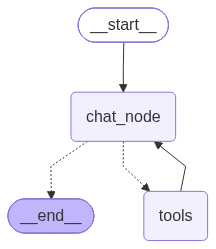

In [37]:
chatbot

In [38]:
# Regular chat
result = chatbot.invoke({"messages": [HumanMessage(content="Hello")]})

print(result["messages"][-1].content)


c:\Users\sajal\OneDrive\Desktop\agentic-chatbot-series\langgraph\Lib\site-packages\langchain_google_genai\chat_models.py:3919: UserWarning: Model 'gemini-3.6-flash' uses fixed sampling defaults; the sampling parameter(s) temperature will be ignored.
  request = self._build_request_config(


[{'type': 'text', 'text': "Hello! How can I help you today? Feel free to ask any questions about the documents or topics you'd like to explore.", 'extras': {'signature': 'EuwBCukBAWkUfRMcM0Bfpc1Ihz6wK1viI2qpbIi/eq34tdTTZOo4EgeazRPeNq36M8x4EAnOCXKh4Qn9uF1lPtnrhvo8tq9x+5H1F9No/PtltnnalaEQb9ZagoFn34fvAzOp9Mey+QzUFNLfCH3rCuODNIyNSly3Zfhe7/uSl3QbcI9qMC8LO/muScxh+IRIPD6EYY50NCuB2TIUZiHe1kTFUauXP1rOOWlHzUzlvUKPz4JsElOPKrK5A964tcB0Llf+PUb6h4z28E45rfPUq3OYMUm2IGrVUkepbL5GPE/Hs0dn4gzcD31rgFRakFQ='}}]


In [39]:
result = chatbot.invoke({"messages": [HumanMessage(content="Using the pdf notes, explain about what are different programming languages used in web development")]})

print(result["messages"][-1].content[0]["text"])

c:\Users\sajal\OneDrive\Desktop\agentic-chatbot-series\langgraph\Lib\site-packages\langchain_google_genai\chat_models.py:3919: UserWarning: Model 'gemini-3.6-flash' uses fixed sampling defaults; the sampling parameter(s) temperature will be ignored.
  request = self._build_request_config(
c:\Users\sajal\OneDrive\Desktop\agentic-chatbot-series\langgraph\Lib\site-packages\langchain_google_genai\chat_models.py:3919: UserWarning: Model 'gemini-3.6-flash' uses fixed sampling defaults; the sampling parameter(s) temperature will be ignored.
  request = self._build_request_config(
c:\Users\sajal\OneDrive\Desktop\agentic-chatbot-series\langgraph\Lib\site-packages\langchain_google_genai\chat_models.py:3919: UserWarning: Model 'gemini-3.6-flash' uses fixed sampling defaults; the sampling parameter(s) temperature will be ignored.
  request = self._build_request_config(


Based on the PDF notes provided, the following programming languages and web technologies are used in web development:

### 1. **JavaScript**
* **Frontend Development:** Used alongside **React.js** to build interactive, dynamic user interfaces for modern web applications (as seen in projects like *CivicFix AI* and *Nexus Core*).
* **Backend Development:** Powered by **Node.js** and web frameworks like **Express.js**, allowing JavaScript to run server-side logic, build APIs, and manage backend service workflows.

### 2. **Python**
* **Backend APIs & AI Integration:** Used with modern web frameworks like **FastAPI** to build scalable REST APIs, handling application backends and seamlessly integrating AI/ML features (such as priority prediction and duplicate detection in *CivicFix AI*).

### 3. **HTML & CSS**
* **HTML (HyperText Markup Language):** The standard markup language used to structure web pages.
* **CSS (Cascading Style Sheets):** Used to style and design the visual layout and r